# Домашнее задание 1 по Food.com

In [ ]:
import os
import gc
import json
import random
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from itertools import product
from models.neighbors import ItemKNN
from models.als import ImplicitALS
from models.ease import EASE
from models.fm import FactorizationMachine
from models.time_svdpp import TimeSVDpp
import ast
from collections import Counter
import hashlib
from pathlib import Path
import shutil
import urllib.request
import zipfile
from scipy import sparse

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_columns', 20)

## Данные

Использую [Food.com Recipes and Interactions](https://www.kaggle.com/datasets/shuyangli94/food-com-recipes-and-user-interactions). Рекомендую новые рецепты по прошлым оценкам пользователя

user_id обозначает пользователя, recipe_id рецепт, date дату отзыва, rating исходную оценку от 0 до 5. У рецептов есть название, ингредиенты, время готовки и дата публикации

Нули исключаю как неоднозначный сигнал. Среди них есть отзывы без выставленной оценки, но считать такие записи показами рецепта нельзя

In [ ]:
VALIDATION_DATE = pd.Timestamp('2008-01-01')
TEST_DATE = pd.Timestamp('2009-01-01')
END_DATE = pd.Timestamp('2010-01-01')
CATALOG_SIZE = 6000
MIN_HISTORY = 10
SOURCE = 'https://www.kaggle.com/datasets/shuyangli94/food-com-recipes-and-user-interactions'
SHA256 = {
    'RAW_interactions.csv': '4e278d2f687b1020f5694e51003a7d6174344b51aebbdf4530de88b5c6a78ee4',
    'RAW_recipes.csv': '6a8136d1da9e03396a9f52d72200b3fddb8fe103f11e1496effca30ac4e0539f',
}

def download_data():
    root = Path(os.environ.get('FOODCOM_RAW', '.cache/raw'))
    root.mkdir(parents=True, exist_ok=True)
    for name, expected in SHA256.items():
        path = root / name
        if not path.exists():
            url = f'https://www.kaggle.com/api/v1/datasets/download/shuyangli94/food-com-recipes-and-user-interactions/{name}'
            temporary = root / (name + '.download')
            urllib.request.urlretrieve(url, temporary)
            if zipfile.is_zipfile(temporary):
                with zipfile.ZipFile(temporary) as archive:
                    with archive.open(name) as source, path.open('wb') as target:
                        shutil.copyfileobj(source, target)
                temporary.unlink()
            else:
                temporary.replace(path)
        digest = hashlib.sha256()
        with path.open('rb') as stream:
            while chunk := stream.read(4 * 1024 * 1024):
                digest.update(chunk)
        if digest.hexdigest() != expected:
            raise ValueError(f'{name}: SHA-256 differs. Check the dataset version before proceeding.')
    return root

def prepare_data(raw_path):
    raw = pd.read_csv(raw_path / 'RAW_interactions.csv', usecols=['user_id', 'recipe_id', 'date', 'rating'])
    recipes = pd.read_csv(raw_path / 'RAW_recipes.csv')
    raw['date'] = pd.to_datetime(raw.date, errors='coerce')
    recipes['submitted'] = pd.to_datetime(recipes.submitted, errors='coerce')
    summary = {
        'raw_events': len(raw), 'raw_users': int(raw.user_id.nunique()),
        'raw_recipes': len(recipes), 'missing_interactions': raw.isna().sum().to_dict(),
        'missing_metadata': recipes.isna().sum().to_dict(),
        'duplicate_events': int(raw.duplicated(['user_id', 'recipe_id', 'date']).sum()),
        'unrated_zero': int((raw.rating == 0).sum()),
    }
    events = raw.dropna(subset=['user_id', 'recipe_id', 'date', 'rating'])
    events = events[events.rating.between(1, 5)].drop_duplicates(['user_id', 'recipe_id', 'date'])
    events = events.merge(recipes[['id', 'name', 'submitted']], left_on='recipe_id', right_on='id', how='inner')
    summary['before_submission'] = int((events.date < events.submitted).sum())
    events = events[events.name.notna() & events.submitted.notna() & (events.date >= events.submitted)].copy()
    assert not events.duplicated(['user_id', 'recipe_id']).any()
    summary['clean_events'] = len(events)
    events = events[events.date < END_DATE].copy()
    summary['events_in_time_window'] = len(events)
    initial_train = events[events.date < VALIDATION_DATE]
    counts = initial_train.groupby('recipe_id').user_id.nunique().rename('users').reset_index()
    catalog_ids = counts.sort_values(['users', 'recipe_id'], ascending=[False, True]).head(CATALOG_SIZE).recipe_id.to_numpy()
    catalog_ids = np.sort(catalog_ids)
    in_catalog = initial_train[initial_train.recipe_id.isin(catalog_ids)]
    user_counts = in_catalog.groupby('user_id').recipe_id.nunique()
    user_ids = np.sort(user_counts[user_counts >= MIN_HISTORY].index.to_numpy())
    selected = events[events.recipe_id.isin(catalog_ids) & events.user_id.isin(user_ids)].copy()
    selected['u'] = np.searchsorted(user_ids, selected.user_id)
    selected['i'] = np.searchsorted(catalog_ids, selected.recipe_id)
    selected['day'] = (selected.date - pd.Timestamp('2000-01-01')).dt.days.astype(float)
    selected = selected[['user_id', 'recipe_id', 'u', 'i', 'rating', 'date', 'day']].sort_values(['date', 'u', 'i']).reset_index(drop=True)
    train = selected[selected.date < VALIDATION_DATE].copy()
    validation = selected[(selected.date >= VALIDATION_DATE) & (selected.date < TEST_DATE)].copy()
    test = selected[selected.date >= TEST_DATE].copy()
    catalog = recipes.set_index('id').loc[catalog_ids].reset_index().rename(columns={'id': 'recipe_id'})
    catalog['i'] = np.arange(len(catalog))
    assert catalog.submitted.max() < VALIDATION_DATE
    assert 100000 <= len(selected) <= 2000000 and len(user_ids) >= 1000 and len(catalog) >= 1000
    assert train.date.max() < validation.date.min() and validation.date.max() < test.date.min()
    summary.update(working_events=len(selected), working_users=len(user_ids), working_recipes=len(catalog),
                   train_events=len(train), validation_events=len(validation), test_events=len(test),
                   sparsity=float(1 - len(selected) / (len(user_ids) * len(catalog))))
    return dict(raw=raw, recipes=recipes, clean=events, events=selected, train=train,
                validation=validation, test=test, catalog=catalog, user_ids=user_ids, summary=summary)

def build_features(catalog):
    ingredients = [ast.literal_eval(x) for x in catalog.ingredients]
    counts = Counter(word for recipe in ingredients for word in set(recipe))
    vocabulary = sorted([word for word, count in counts.items() if count >= 20])
    ingredient_ids = {word: len(catalog) + 1 + j for j, word in enumerate(vocabulary)}
    numeric_start = len(catalog) + 1 + len(vocabulary)
    numeric = catalog[['minutes', 'n_steps', 'n_ingredients']].to_numpy(float)
    invalid_minutes = (numeric[:, 0] <= 0) | (numeric[:, 0] > 1440)
    valid_minutes = numeric[~invalid_minutes, 0]
    numeric[invalid_minutes, 0] = np.median(valid_minutes)
    numeric = np.log1p(np.clip(numeric, 0, None))
    lower, upper = np.quantile(numeric, [.01, .99], axis=0)
    numeric = (np.clip(numeric, lower, upper) - lower) / np.maximum(upper - lower, 1e-8)
    rows, vals = [], []
    for i, words in enumerate(ingredients):
        tokens = [ingredient_ids[word] for word in sorted(set(words)) if word in ingredient_ids]
        rows.append([i + 1] + tokens + list(range(numeric_start, numeric_start + 3)))
        vals.append([1.] + [1 / np.sqrt(max(len(tokens), 1))] * len(tokens) + list(numeric[i]))
    width = max(map(len, rows))
    ids = np.zeros((len(rows), width), dtype=np.int64)
    values = np.zeros_like(ids, dtype=np.float32)
    for i, (row, val) in enumerate(zip(rows, vals)):
        ids[i, :len(row)] = row
        values[i, :len(row)] = val
    details = {'ingredient_features': len(vocabulary), 'numeric_features': 3,
               'invalid_minutes_imputed': int(invalid_minutes.sum()), 'max_nonzero_item_features': width,
               'numeric_lower': lower.tolist(), 'numeric_upper': upper.tolist(),
               'vocabulary': vocabulary}
    return (ids, values, numeric_start + 3), details

def coverage_report(data):
    rows = []
    all_events, catalog = data['clean'], set(data['catalog'].recipe_id)
    users = set(data['user_ids'])
    for label, start, end in [('validation', VALIDATION_DATE, TEST_DATE), ('test', TEST_DATE, END_DATE)]:
        period = all_events[(all_events.date >= start) & (all_events.date < end)]
        history = all_events[all_events.date < start]
        seen_users, seen_items = set(history.user_id), set(history.recipe_id)
        rows.append({'period': label, 'all_clean_events': len(period),
                     'cold_user_events': int((~period.user_id.isin(seen_users)).sum()),
                     'cold_item_events': int((~period.recipe_id.isin(seen_items)).sum()),
                     'selected_events': int((period.user_id.isin(users) & period.recipe_id.isin(catalog)).sum())})
    return pd.DataFrame(rows)

In [ ]:
raw_path = download_data()
data = prepare_data(raw_path)
train, validation, test = data['train'], data['validation'], data['test']
catalog = data['catalog']
n_users, n_items = len(data['user_ids']), len(catalog)
features, feature_info = build_features(catalog)

display(data['raw'].head())
display(data['recipes'][['id', 'name', 'minutes', 'n_steps', 'n_ingredients']].head())

,user_id,recipe_id,date,rating
0,38094,40893,2003-02-17,4
1,1293707,40893,2011-12-21,5
2,8937,44394,2002-12-01,4
3,126440,85009,2010-02-27,5
4,57222,85009,2011-10-01,5


,id,name,minutes,n_steps,n_ingredients
0,137739,arriba baked winter squash mexican style,55,11,7
1,31490,a bit different breakfast pizza,30,9,6
2,112140,all in the kitchen chili,130,6,13
3,59389,alouette potatoes,45,11,11
4,44061,amish tomato ketchup for canning,190,5,8


In [ ]:
print(f"Исходные данные  {len(data['raw']):,} взаимодействий, "
      f"{data['raw'].user_id.nunique():,} пользователей, {len(data['recipes']):,} рецептов".replace(',', ' '))
print(f"После очистки  {data['summary']['clean_events']:,} взаимодействий".replace(',', ' '))
print(f"После ограничения датой  {data['summary']['events_in_time_window']:,} взаимодействий".replace(',', ' '))
print(f"Рабочая выборка  {len(data['events']):,} взаимодействий, "
      f"{n_users:,} пользователей, {n_items:,} рецептов".replace(',', ' '))

sizes = pd.DataFrame([
    {'Выборка': name, 'Взаимодействия': len(frame), 'Пользователи': frame.u.nunique(),
     'Рецепты с отзывами': frame.i.nunique(), 'Доля взаимодействий': len(frame) / len(data['events'])}
    for name, frame in [('Train', train), ('Validation', validation), ('Test', test)]
])
display(sizes.assign(**{'Доля взаимодействий': sizes['Доля взаимодействий'].map(lambda value: f'{value:.1%}')}))

display(pd.Series({
    'Дубликаты по пользователю, рецепту и дате': data['summary']['duplicate_events'],
    'Записи с оценкой 0': data['summary']['unrated_zero'],
    'Отзывы раньше публикации рецепта': data['summary']['before_submission'],
}, name='Число записей').to_frame())

missing = pd.DataFrame({
    'Пропуски в отзывах': pd.Series(data['summary']['missing_interactions']),
    'Пропуски в рецептах': pd.Series(data['summary']['missing_metadata'])
}).astype('Int64').astype('string').fillna('')
display(missing.rename_axis('Поле'))

Исходные данные  1 132 367 взаимодействий  226 570 пользователей  231 637 рецептов
После очистки  1 070 294 взаимодействий
После ограничения датой  704 894 взаимодействий
Рабочая выборка  118 930 взаимодействий  2 848 пользователей  6 000 рецептов


,Выборка,Взаимодействия,Пользователи,Рецепты с отзывами,Доля взаимодействий
0,Train,93688,2848,5996,78.8%
1,Validation,15216,1836,4192,12.8%
2,Test,10026,1551,3489,8.4%


,Число записей
"Дубликаты по пользователю, рецепту и дате",0
Записи с оценкой 0,60847
Отзывы раньше публикации рецепта,1226


,Пропуски в отзывах,Пропуски в рецептах
Поле,,
contributor_id,,0
date,0,
description,,4979
id,,0
ingredients,,0
minutes,,0
n_ingredients,,0
n_steps,,0
name,,1


## EDA и подготовка

Удаляю нули, пропуски основных полей, дубликаты и отзывы раньше публикации рецепта. Пустые описания оставляю, в моделях они не используются

Беру 6000 популярных в train рецептов и пользователей с минимум 10 такими рецептами в train. При равной популярности сортирую по recipe_id. Ограничение каталога нужно для памяти EASE, будущие оценки в отбор не входят

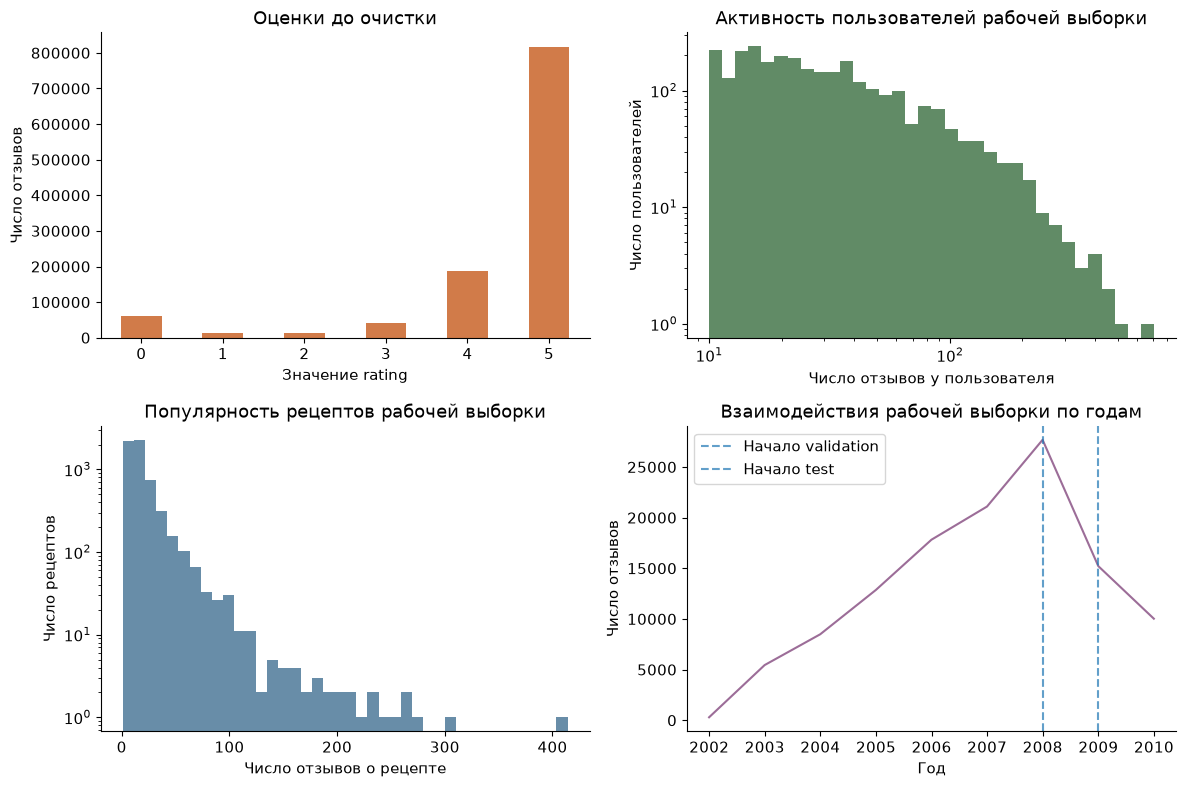

,Отзывов у пользователя,Отзывов о рецепте
Количество,2848.00,5999.00
Среднее,41.76,19.82
Стандартное отклонение,48.54,21.37
Минимум,10.00,1.00
25-й процентиль,16.00,10.00
Медиана,26.00,14.00
75-й процентиль,46.00,22.00
Максимум,702.00,414.00


Разреженность матрицы пользователей и рецептов  99.30%


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
data['raw'].rating.value_counts().sort_index().plot.bar(ax=axes[0, 0], color='#d17b49', rot=0)
axes[0, 0].set(title='Оценки до очистки', xlabel='Значение rating', ylabel='Число отзывов')
activity = data['events'].groupby('u').size()
popularity = data['events'].groupby('i').size()
axes[0, 1].hist(activity, bins=np.geomspace(activity.min(), activity.max() + 1, 35), color='#618b66')
axes[0, 1].set(xscale='log', yscale='log', title='Активность пользователей рабочей выборки',
               xlabel='Число отзывов у пользователя', ylabel='Число пользователей')
axes[1, 0].hist(popularity, bins=40, color='#688da8')
axes[1, 0].set(yscale='log', title='Популярность рецептов рабочей выборки',
               xlabel='Число отзывов о рецепте', ylabel='Число рецептов')
annual = data['events'].set_index('date').resample('YE').size()
axes[1, 1].plot(annual.index, annual.values, color='#9c6d98')
for cutoff, label in [(VALIDATION_DATE, 'Начало validation'), (TEST_DATE, 'Начало test')]:
    axes[1, 1].axvline(cutoff, linestyle='--', alpha=.7, label=label)
axes[1, 1].set(title='Взаимодействия рабочей выборки по годам', xlabel='Год', ylabel='Число отзывов')
axes[1, 1].legend()
plt.tight_layout()
plt.show()

statistics = pd.DataFrame({
    'Отзывов у пользователя': activity.describe(),
    'Отзывов о рецепте': popularity.describe()
}).rename(index={'count': 'Количество', 'mean': 'Среднее', 'std': 'Стандартное отклонение',
                 'min': 'Минимум', '25%': '25-й процентиль', '50%': 'Медиана',
                 '75%': '75-й процентиль', 'max': 'Максимум'})
display(statistics.round(2))
print(f"Разреженность матрицы пользователей и рецептов  {data['summary']['sparsity']:.2%}")

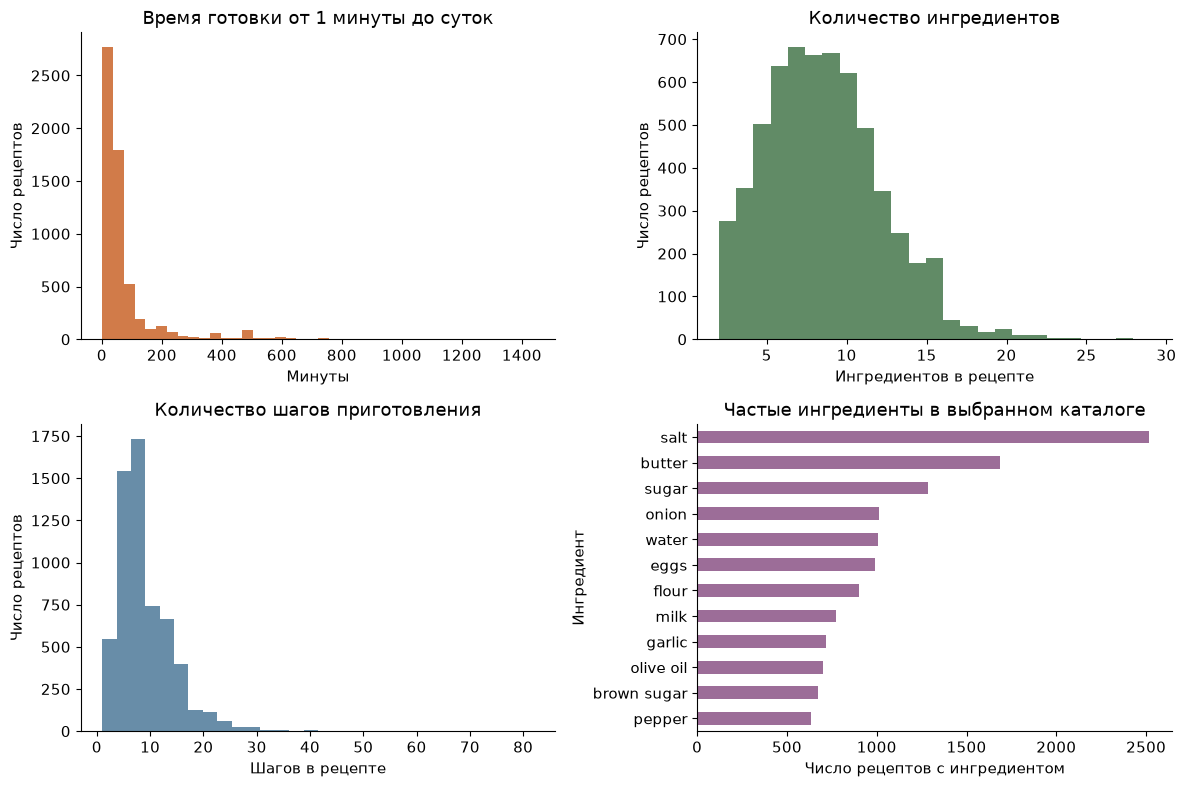

Ингредиентов в словаре FM 362
Значений времени 0 или больше суток 82


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
reasonable = catalog.minutes.between(1, 1440)
axes[0, 0].hist(catalog.loc[reasonable, 'minutes'], bins=40, color='#d17b49')
axes[0, 0].set(title='Время готовки от 1 минуты до суток', xlabel='Минуты', ylabel='Число рецептов')
axes[0, 1].hist(catalog.n_ingredients, bins=25, color='#618b66')
axes[0, 1].set(title='Количество ингредиентов', xlabel='Ингредиентов в рецепте', ylabel='Число рецептов')
axes[1, 0].hist(catalog.n_steps, bins=30, color='#688da8')
axes[1, 0].set(title='Количество шагов приготовления', xlabel='Шагов в рецепте', ylabel='Число рецептов')
ingredient_counts = Counter(word for value in catalog.ingredients for word in set(ast.literal_eval(value)))
common = pd.Series(dict(ingredient_counts.most_common(12))).sort_values()
common.plot.barh(ax=axes[1, 1], color='#9c6d98')
axes[1, 1].set(title='Частые ингредиенты в выбранном каталоге', xlabel='Число рецептов с ингредиентом', ylabel='Ингредиент')
plt.tight_layout()
plt.show()

print('Ингредиентов в словаре FM', feature_info['ingredient_features'])
print('Значений времени 0 или больше суток', feature_info['invalid_minutes_imputed'])

## Протокол оценки

Train до 01.01.2008, validation 2008 год, test 2009 год. Более поздние события исключаю. После отбора доли составляют примерно 79/13/8%. Годовые периоды ограничивают горизонт выдачи; границы выбраны по объёму данных до обучения моделей. Параметры выбираю по validation NDCG@10. Итоговое сравнение на test рассматриваю как исследовательское

На начало периода выдаю один top-10 из всего каталога, исключая ранее оценённые рецепты. При равных score сортирую по recipe_id. Все рецепты опубликованы до первого cutoff. Новых пользователей и объекты исключаю, потери показаны ниже

Релевантным считаю новый для пользователя рецепт с будущей оценкой 4 или 5. Это выбранный порог положительного отклика на пятибалльной шкале, а не готовая метка из датасета. Оценки 1, 2 и 3 не считаю достаточно высоким откликом для этой задачи. Порог одинаковый у всех моделей и не меняется при подборе параметров

Метрики усредняю по пользователям с хотя бы одним таким объектом. Пользователи, кандидаты и релевантность одинаковы для всех моделей

Подбираю настройки по NDCG@10 важен порядок подходящих блюд. Recall@10 показывает, какую долю понравившихся рецептов удалось найти

$$NDCG_u@10=\frac{\sum_{j=1}^{10}rel_{uj}/\log_2(j+1)}{\sum_{j=1}^{\min(10,|G_u|)}1/\log_2(j+1)},\qquad Recall_u@10=\frac{|R_u^{10}\cap G_u|}{|G_u|}.$$

In [ ]:
class Popularity:
    def fit(self, events, n_users, n_items, **kwargs):
        self.counts = np.bincount(events.loc[events.rating >= 4, 'i'], minlength=n_items).astype(float)
        return self

    def score(self, users, **kwargs):
        return np.broadcast_to(self.counts, (len(users), len(self.counts))).copy()


def make_protocol(history, future, n_users, n_items, day):
    seen = sparse.csr_matrix((np.ones(len(history)), (history.u, history.i)), shape=(n_users, n_items))
    positive = future[future.rating >= 4].drop_duplicates(['u', 'i'])
    positive = positive[np.asarray(seen[positive.u.to_numpy(), positive.i.to_numpy()]).ravel() == 0]
    truth = {int(u): set(group.i) for u, group in positive.groupby('u')}
    users = np.array(sorted(truth), dtype=np.int64)
    assert len(users) > 0 and np.all(n_items - np.diff(seen.indptr)[users] >= 10)
    return dict(users=users, truth=truth, seen=seen, day=day, n_items=n_items)


def topk(model, protocol, k=10, batch_size=128):
    result = []
    for start in range(0, len(protocol['users']), batch_size):
        users = protocol['users'][start:start + batch_size]
        scores = np.asarray(model.score(users, day=protocol['day']), dtype=np.float64)
        assert scores.shape == (len(users), protocol['n_items']) and np.isfinite(scores).all()
        mask = protocol['seen'][users].tocoo()
        scores[mask.row, mask.col] = -np.inf

        chosen = np.argsort(-scores, axis=1, kind='stable')[:, :k]
        assert np.isfinite(np.take_along_axis(scores, chosen, axis=1)).all()
        result.append(chosen)
    return np.vstack(result)


def user_metrics(recommendations, protocol, k=10):
    rows = []
    discount = 1 / np.log2(np.arange(2, k + 2))
    for u, recs in zip(protocol['users'], recommendations):
        relevant = protocol['truth'][int(u)]
        assert len(recs) == len(set(recs)) == k
        assert protocol['seen'][u, recs].sum() == 0
        hits = np.array([int(i) in relevant for i in recs])
        ideal = discount[:min(k, len(relevant))].sum()
        rows.append({'u': int(u), 'NDCG@10': float((hits * discount).sum() / ideal),
                     'Recall@10': float(hits.sum() / len(relevant)), 'HitRate@10': float(hits.any())})
    return pd.DataFrame(rows).set_index('u')


def evaluate(model, protocol):
    recs = topk(model, protocol)
    per_user = user_metrics(recs, protocol)
    metrics = per_user.mean().to_dict()
    metrics['CatalogCoverage@10'] = len(np.unique(recs)) / protocol['n_items']
    return metrics, per_user, recs


MODELS = {'Popularity': Popularity, 'ItemKNN': ItemKNN, 'ALS': ImplicitALS,
          'EASE': EASE, 'FM': FactorizationMachine, 'timeSVD++': TimeSVDpp}

In [ ]:
day_of = lambda date: float((date - pd.Timestamp('2000-01-01')).days)
valid_protocol = make_protocol(train, validation, n_users, n_items, day_of(VALIDATION_DATE))
display(coverage_report(data))
print('Пользователей с новым положительным рецептом на validation:', len(valid_protocol['users']))
print('Всего рецептов в каталоге:', n_items)
print('Медианное число доступных кандидатов:',
      np.median(n_items - np.diff(valid_protocol['seen'].indptr)[valid_protocol['users']]))

,period,all_clean_events,cold_user_events,cold_item_events,selected_events
0,validation,161222,44182,54157,15216
1,test,153432,38404,44367,10026


Пользователей с новым положительным рецептом на validation: 1824
Всего рецептов в каталоге: 6000
Медианное число доступных кандидатов: 5978.5


## Модели

### Item-based CF

На бинарной матрице оценок не ниже 4 считаю cosine со shrinkage по числу общих пользователей

$$s_{ij}=\frac{X_i^TX_j}{\|X_i\|\|X_j\|}\frac{n_{ij}}{n_{ij}+h},\qquad s_{ii}=0.$$

Оставляю k соседей для каждого рецепта. Score сумма сходств с понравившимися блюдами $\hat S=XS$

### iALS

Предсказываю бинарное предпочтение $p_{ui}=1$ для оценки 4 или 5, иначе 0. У наблюдавшихся положительных пар confidence $c_{ui}=1+\alpha$, у остальных 1

$$\min_{X,Y}\sum_{u,i}c_{ui}(p_{ui}-x_u^Ty_i)^2+\lambda(\|X\|_F^2+\|Y\|_F^2).$$

$$x_u=(Y^TY+\alpha\sum_{i:p_{ui}=1}y_iy_i^T+\lambda I)^{-1}(1+\alpha)\sum_{i:p_{ui}=1}y_i.$$

Обновление объектов симметрично, score равен $XY^T$. Неизвестная пара имеет меньшую уверенность, чем положительная. Низкие оценки входят в нулевой таргет и исключаются из выдачи как известные

### EASE

$$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2,\qquad diag(B)=0.$$

Если $P=(X^TX+\lambda I)^{-1}$, то $B_{ij}=-P_{ij}/P_{jj}$ для $i\ne j$, а score равен $XB$. Использую разложение Холецкого.

### FM

$$f(x)=w_0+\sum_a w_ax_a+\frac12\sum_f\left[(\sum_a v_{af}x_a)^2-\sum_a v_{af}^2x_a^2\right].$$

К ID добавляю ингредиенты, время готовки, число шагов и ингредиентов. Они описывают вкус и сложность блюда. Словарь и масштабы строятся на train-каталоге. Редкие ингредиенты убираю, числовые признаки логарифмирую и масштабирую. Будущие отзывы и оценки в признаки не входят

Loss $\log(1+\exp(f(u,j)-f(u,i)))$. Позитив имеет оценку 4 или 5, негатив беру из оценок 1-3 или неизвестных рецептов. Неизвестный негатив может оказаться хорошим блюдом.

### timeSVD++

$$\hat r_{ui}(t)=\mu+b_u+\alpha_ud_u(t)+b_i+b_{i,bin(t)}+q_i^T\left(p_u+a_ud_u(t)+\frac{1}{\sqrt{|N(u)|}}\sum_{j\in N(u)}y_j\right),$$
$$d_u(t)=sign(t-\bar t_u)\left|\frac{t-\bar t_u}{365.25}\right|^{0.4}.$$

Учитываю всю обучающую историю $N(u)$, drift пользователя и годовые item-bin смещения. Обучаю MSE с L2 через Adam. Отдельных user-day параметров нет. Для будущего беру последний item-bin и экстраполирую drift. Время рекомендации одинаково у всех моделей

## Подбор параметров

Выбираю максимальный validation NDCG@10, при равенстве первый вариант. Batch FM до 2048 пар, timeSVD++ до 128 пользователей с историями

In [ ]:
GRIDS = {
    'ItemKNN': dict(neighbors=[150, 400], shrinkage=[20, 100]),
    'ALS': dict(factors=[32, 64], regularization=[.1, 1.], alpha=[10., 40.], iterations=[20]),
    'EASE': dict(regularization=[100., 300., 1000., 3000.]),
    'FM': dict(factors=[32], regularization=[.000001, .0001], epochs=[20, 60], learning_rate=[.003, .01]),
    'timeSVD++': dict(factors=[16], regularization=[.00001, .01], epochs=[25, 75], learning_rate=[.01], bin_days=[365], beta=[.4]),
}

def parameter_grid(grid):
    keys = list(grid)
    return [dict(zip(keys, values)) for values in product(*(grid[key] for key in keys))]

display(pd.DataFrame([{'model': name, 'trials': len(parameter_grid(grid)), 'grid': json.dumps(grid)}
                      for name, grid in GRIDS.items()]))

,model,trials,grid
0,ItemKNN,4,"{""neighbors"": [150, 400], ""shrinkage"": [20, 100]}"
1,ALS,8,"{""factors"": [32, 64], ""regularization"": [0.1, 1.0], ""alpha"": [10.0, 40.0], ""iterations"": [20]}"
2,EASE,4,"{""regularization"": [100.0, 300.0, 1000.0, 3000.0]}"
3,FM,8,"{""factors"": [32], ""regularization"": [1e-06, 0.0001], ""epochs"": [20, 60], ""learning_rate"": [0.003..."
4,timeSVD++,4,"{""factors"": [16], ""regularization"": [1e-05, 0.01], ""epochs"": [25, 75], ""learning_rate"": [0.01], ..."


In [ ]:
search_rows, selected, validation_curves = [], {}, {}
for name, grid in GRIDS.items():
    best_metric = -np.inf
    for params in parameter_grid(grid):
        started = perf_counter()
        model = MODELS[name](**params)
        model.fit(train, n_users, n_items, features=features)
        train_seconds = perf_counter() - started
        metrics, _, _ = evaluate(model, valid_protocol)
        row = {'model': name, 'params': json.dumps(params, sort_keys=True),
               'train_seconds': train_seconds, **metrics}
        search_rows.append(row)
        print(f"{name}: {params} -> NDCG@10={metrics['NDCG@10']:.5f}, Recall@10={metrics['Recall@10']:.5f}, fit={train_seconds:.1f}s", flush=True)
        if metrics['NDCG@10'] > best_metric:
            best_metric = metrics['NDCG@10']
            selected[name] = params.copy()
            validation_curves[name] = list(getattr(model, 'loss_history', []))
        del model
        gc.collect()
search = pd.DataFrame(search_rows)
display(search.sort_values(['model', 'NDCG@10'], ascending=[True, False]).reset_index(drop=True))

ItemKNN: {'neighbors': 150, 'shrinkage': 20} -> NDCG@10=0.02418, Recall@10=0.02248, fit=2.8s
ItemKNN: {'neighbors': 150, 'shrinkage': 100} -> NDCG@10=0.02379, Recall@10=0.02237, fit=2.9s
ItemKNN: {'neighbors': 400, 'shrinkage': 20} -> NDCG@10=0.02491, Recall@10=0.02296, fit=4.6s
ItemKNN: {'neighbors': 400, 'shrinkage': 100} -> NDCG@10=0.02476, Recall@10=0.02350, fit=4.4s
ALS: {'factors': 32, 'regularization': 0.1, 'alpha': 10.0, 'iterations': 20} -> NDCG@10=0.02250, Recall@10=0.01915, fit=15.4s
ALS: {'factors': 32, 'regularization': 0.1, 'alpha': 40.0, 'iterations': 20} -> NDCG@10=0.01822, Recall@10=0.01656, fit=14.4s
ALS: {'factors': 32, 'regularization': 1.0, 'alpha': 10.0, 'iterations': 20} -> NDCG@10=0.02314, Recall@10=0.01998, fit=14.8s
ALS: {'factors': 32, 'regularization': 1.0, 'alpha': 40.0, 'iterations': 20} -> NDCG@10=0.01823, Recall@10=0.01620, fit=15.9s
ALS: {'factors': 64, 'regularization': 0.1, 'alpha': 10.0, 'iterations': 20} -> NDCG@10=0.02120, Recall@10=0.01906, fit=27

,model,params,train_seconds,NDCG@10,Recall@10,HitRate@10,CatalogCoverage@10
0,ALS,"{""alpha"": 10.0, ""factors"": 32, ""iterations"": 20, ""regularization"": 1.0}",14.792498,0.023143,0.019981,0.133224,0.132167
1,ALS,"{""alpha"": 10.0, ""factors"": 32, ""iterations"": 20, ""regularization"": 0.1}",15.447895,0.022500,0.019150,0.129934,0.132667
2,ALS,"{""alpha"": 10.0, ""factors"": 64, ""iterations"": 20, ""regularization"": 0.1}",27.645585,0.021200,0.019056,0.120614,0.187333
3,ALS,"{""alpha"": 10.0, ""factors"": 64, ""iterations"": 20, ""regularization"": 1.0}",28.627675,0.021097,0.018919,0.121162,0.185333
4,ALS,"{""alpha"": 40.0, ""factors"": 32, ""iterations"": 20, ""regularization"": 1.0}",15.914004,0.018232,0.016200,0.114583,0.224833
5,ALS,"{""alpha"": 40.0, ""factors"": 32, ""iterations"": 20, ""regularization"": 0.1}",14.371568,0.018219,0.016562,0.115680,0.224000
6,ALS,"{""alpha"": 40.0, ""factors"": 64, ""iterations"": 20, ""regularization"": 0.1}",27.692370,0.017358,0.015985,0.105811,0.281500
7,ALS,"{""alpha"": 40.0, ""factors"": 64, ""iterations"": 20, ""regularization"": 1.0}",27.898447,0.016361,0.014226,0.098136,0.281333
8,EASE,"{""regularization"": 1000.0}",6.222634,0.027916,0.025865,0.148575,0.065667
9,EASE,"{""regularization"": 300.0}",6.340090,0.027492,0.025518,0.148575,0.126000


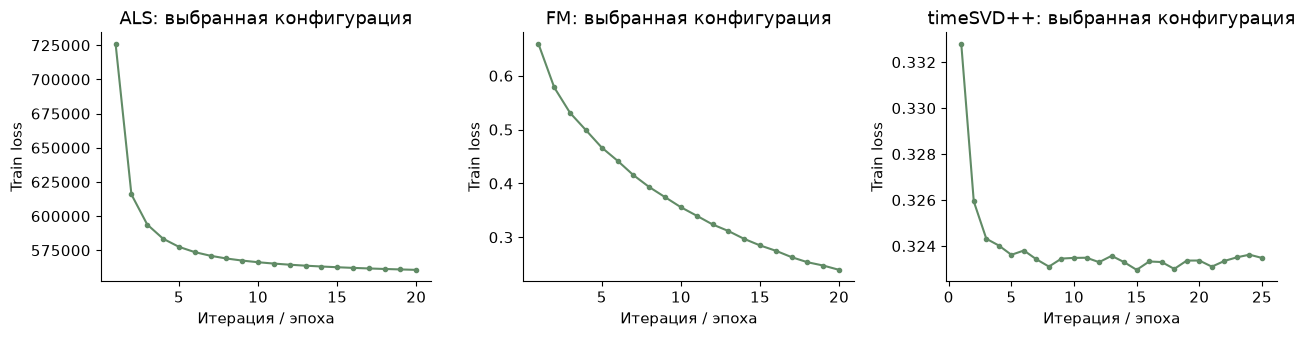

,model,NDCG@10,Recall@10,params
0,EASE,0.027916,0.025865,"{""regularization"": 1000.0}"
1,ItemKNN,0.024905,0.022964,"{""neighbors"": 400, ""shrinkage"": 20}"
2,ALS,0.023143,0.019981,"{""alpha"": 10.0, ""factors"": 32, ""iterations"": 20, ""regularization"": 1.0}"
3,FM,0.020260,0.018200,"{""epochs"": 20, ""factors"": 32, ""learning_rate"": 0.003, ""regularization"": 1e-06}"
4,timeSVD++,0.012722,0.008941,"{""beta"": 0.4, ""bin_days"": 365, ""epochs"": 25, ""factors"": 16, ""learning_rate"": 0.01, ""regularizati..."


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, name in zip(axes, ['ALS', 'FM', 'timeSVD++']):
    curve = validation_curves[name]
    ax.plot(np.arange(1, len(curve) + 1), curve, marker='.', color='#618b66')
    ax.set(title=f'{name}: выбранная конфигурация', xlabel='Итерация / эпоха', ylabel='Train loss')
plt.tight_layout()
plt.show()
display(search.sort_values('NDCG@10', ascending=False).groupby('model', sort=False).head(1)
        [['model', 'NDCG@10', 'Recall@10', 'params']].reset_index(drop=True))

## Сравнение на test

После выбора настроек обучаю модели на объединённых train и validation. Рецепты из обеих частей исключаю из выдачи, затем считаю метрики на test

Для проверки метаданных добавляю FM только с ID, для проверки временных компонентов статический SVD++. У них те же настройки, что у полных моделей

In [ ]:
frozen_params = {name: params.copy() for name, params in selected.items()}
development = pd.concat([train, validation], ignore_index=True).sort_values(['date', 'u', 'i'])
test_protocol = make_protocol(development, test, n_users, n_items, day_of(TEST_DATE))
print('Финальная история:', len(development), 'отзывов')
print('Общий набор оценочных пользователей test:', len(test_protocol['users']))
print('Новых релевантных user-recipe пар:', sum(map(len, test_protocol['truth'].values())))
print('Медианное число кандидатов:', np.median(n_items - np.diff(test_protocol['seen'].indptr)[test_protocol['users']]))

Финальная история: 108904 отзывов
Общий набор оценочных пользователей test: 1538
Новых релевантных user-recipe пар: 9542
Медианное число кандидатов: 5969.5


In [ ]:
final_rows, recommendations = [], {}
specifications = [('Popularity', 'Popularity', {}), *[(name, name, params) for name, params in frozen_params.items()],
                  ('FM: только ID', 'FM', {**frozen_params['FM'], 'metadata': False}),
                  ('SVD++: без времени', 'timeSVD++', {**frozen_params['timeSVD++'], 'temporal': False})]
for label, name, params in specifications:
    started = perf_counter()
    model = MODELS[name](**params)
    model.fit(development, n_users, n_items, features=features)
    fit_seconds = perf_counter() - started
    started = perf_counter()
    metrics, _, recs = evaluate(model, test_protocol)
    score_seconds = perf_counter() - started
    final_rows.append({'model': label, **metrics, 'train_seconds': fit_seconds,
                       'rank_seconds': score_seconds, 'params': json.dumps(params, sort_keys=True)})
    recommendations[label] = recs
    print(f"{label}: NDCG@10={metrics['NDCG@10']:.5f}, Recall@10={metrics['Recall@10']:.5f}, fit={fit_seconds:.1f}s", flush=True)
    del model
    gc.collect()
results = pd.DataFrame(final_rows).set_index('model')
display(results.round(5))

Popularity: NDCG@10=0.01681, Recall@10=0.02131, fit=0.0s
ItemKNN: NDCG@10=0.01766, Recall@10=0.01915, fit=5.2s
ALS: NDCG@10=0.02139, Recall@10=0.02459, fit=15.7s
EASE: NDCG@10=0.01842, Recall@10=0.01854, fit=7.0s
FM: NDCG@10=0.01751, Recall@10=0.02010, fit=70.4s
timeSVD++: NDCG@10=0.01584, Recall@10=0.01743, fit=8.0s
FM: только ID: NDCG@10=0.01153, Recall@10=0.01280, fit=29.7s
SVD++: без времени: NDCG@10=0.01162, Recall@10=0.01266, fit=6.7s


,NDCG@10,Recall@10,HitRate@10,CatalogCoverage@10,train_seconds,rank_seconds,params
model,,,,,,,
Popularity,0.01681,0.02131,0.10403,0.00617,0.00344,1.42329,{}
ItemKNN,0.01766,0.01915,0.10143,0.08983,5.19777,2.99103,"{""neighbors"": 400, ""shrinkage"": 20}"
ALS,0.02139,0.02459,0.11638,0.13767,15.65618,2.10390,"{""alpha"": 10.0, ""factors"": 32, ""iterations"": 20, ""regularization"": 1.0}"
EASE,0.01842,0.01854,0.10338,0.05400,6.96605,8.35600,"{""regularization"": 1000.0}"
FM,0.01751,0.02010,0.10533,0.10050,70.40692,2.05444,"{""epochs"": 20, ""factors"": 32, ""learning_rate"": 0.003, ""regularization"": 1e-06}"
timeSVD++,0.01584,0.01743,0.08583,0.00333,8.00253,2.09059,"{""beta"": 0.4, ""bin_days"": 365, ""epochs"": 25, ""factors"": 16, ""learning_rate"": 0.01, ""regularizati..."
FM: только ID,0.01153,0.01280,0.06762,0.19050,29.68819,2.28084,"{""epochs"": 20, ""factors"": 32, ""learning_rate"": 0.003, ""metadata"": false, ""regularization"": 1e-06}"
SVD++: без времени,0.01162,0.01266,0.06762,0.00300,6.68168,2.07888,"{""beta"": 0.4, ""bin_days"": 365, ""epochs"": 25, ""factors"": 16, ""learning_rate"": 0.01, ""regularizati..."


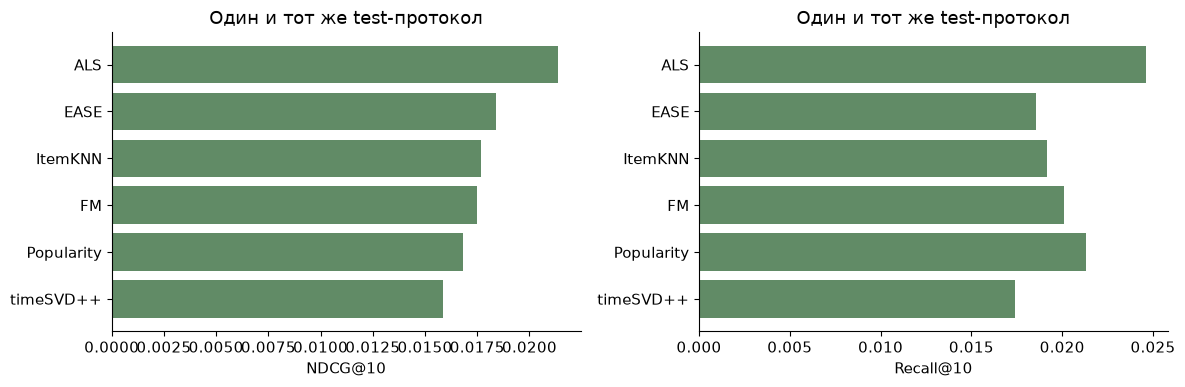

,NDCG@10,Recall@10,HitRate@10,CatalogCoverage@10,train_seconds,rank_seconds,params
model,,,,,,,
ALS,0.02139,0.02459,0.11638,0.13767,15.65618,2.10390,"{""alpha"": 10.0, ""factors"": 32, ""iterations"": 20, ""regularization"": 1.0}"
EASE,0.01842,0.01854,0.10338,0.05400,6.96605,8.35600,"{""regularization"": 1000.0}"
ItemKNN,0.01766,0.01915,0.10143,0.08983,5.19777,2.99103,"{""neighbors"": 400, ""shrinkage"": 20}"
FM,0.01751,0.02010,0.10533,0.10050,70.40692,2.05444,"{""epochs"": 20, ""factors"": 32, ""learning_rate"": 0.003, ""regularization"": 1e-06}"
Popularity,0.01681,0.02131,0.10403,0.00617,0.00344,1.42329,{}
timeSVD++,0.01584,0.01743,0.08583,0.00333,8.00253,2.09059,"{""beta"": 0.4, ""bin_days"": 365, ""epochs"": 25, ""factors"": 16, ""learning_rate"": 0.01, ""regularizati..."


In [ ]:
main_names = ['Popularity', 'ItemKNN', 'ALS', 'EASE', 'FM', 'timeSVD++']
table = results.loc[main_names].sort_values('NDCG@10', ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['NDCG@10', 'Recall@10']):
    ax.barh(table.index[::-1], table[metric].iloc[::-1], color='#618b66')
    ax.set(xlabel=metric, title='Один и тот же test-протокол')
plt.tight_layout()
plt.show()
display(table[['NDCG@10', 'Recall@10', 'HitRate@10', 'CatalogCoverage@10', 'train_seconds', 'rank_seconds', 'params']].round(5))

## Примеры рекомендаций

Три пользователя с минимальным ID, медианной и максимальной длиной истории. Ниже их недавние положительные оценки и top-10 каждой модели

In [ ]:
lengths = development.groupby('u').size().reindex(test_protocol['users'])
ordered_users = lengths.rename('n').reset_index().sort_values(['n', 'u'])
example_users = list(dict.fromkeys([int(test_protocol['users'][0]), int(ordered_users.iloc[len(ordered_users)//2].u),
                                   int(ordered_users.iloc[-1].u)]))
position = {int(u): j for j, u in enumerate(test_protocol['users'])}
for u in example_users:
    display(Markdown(f"**Пользователь {int(data['user_ids'][u])}, {int(lengths.loc[u])} оценок до test**"))
    liked = development[(development.u == u) & (development.rating >= 4)].tail(5)
    display(liked[['i', 'rating', 'date']].merge(catalog[['i', 'name']], on='i')[['name', 'rating', 'date']])
    for name in main_names[1:]:
        ids = recommendations[name][position[u]]
        titles = catalog.iloc[ids].name.to_list()
        display(Markdown(f"**{name}:** " + '; '.join(titles)))

**Пользователь 1535, 194 оценок до test**

,name,rating,date
0,one dish chicken bake,4,2008-05-21
1,island honey burgers,4,2008-05-27
2,the only chocolate cake recipe you ll ever need devil s food,5,2008-07-12
3,big sandwich spread,5,2008-08-04
4,crock pot whole chicken,4,2008-10-22


**ItemKNN:** kittencal s 5 minute cinnamon flop brunch cake; grilled cheese  diner style; jo mama s world famous spaghetti; japanese mum s chicken; oven fried chicken chimichangas; whatever floats your boat  brownies; banana banana bread; crock pot chicken with black beans   cream cheese; pork chops yum yum; tiny cinnamon rolls

**ALS:** dark chocolate cake; whatever floats your boat  brownies; big grandma s best peanut butter cookies; thick chocolate pudding; best ever banana cake with cream cheese frosting; southwestern baked spaghetti; kittencal s chocolate frosting icing; better than sex cake iii; hello dollies; mean chef s apple brine

**EASE:** kittencal s 5 minute cinnamon flop brunch cake; grilled cheese  diner style; whatever floats your boat  brownies; jo mama s world famous spaghetti; banana banana bread; oven fried chicken chimichangas; pork chops yum yum; japanese mum s chicken; my family s favorite sloppy joes  pizza joes; crock pot chicken with black beans   cream cheese

...

**ItemKNN:** to die for crock pot roast; japanese mum s chicken; kittencal s chicken crescent roll casserole; crumb topped banana muffins; kittencal s moist cheddar garlic oven fried chicken breast; so it s bekah s pulled pork now; mashed red potatoes with garlic and parmesan; best ever banana cake with cream cheese frosting; mean guy s general tso s chicken; kittencal s famous greek salad

**ALS:** my no roll pie crust; chicken garlic bites; bobbie q sauce  barbecue sauce; sharon s ono barbecue beef; denny s style french toast; kittencal s banana cinnamon snack cake or muffins  low fat; individual cream cheese danish; copycat ihop harvest grain   nut pancakes; kittencal s easy one bowl vanilla cupcakes; strawberry coffee cake

**EASE:** to die for crock pot roast; japanese mum s chicken; kittencal s chicken crescent roll casserole; crumb topped banana muffins; so it s bekah s pulled pork now; kittencal s famous greek salad; best ever banana cake with cream cheese frosting; kittencal s moist cheddar garlic oven fried chicken breast; mashed red potatoes with garlic and parmesan; chocolate  chocolate  chocolate  bundt cake with chocolate glaze

**FM:** peanut butter cup cookies  tarts; beef patties in onion gravy; oatmeal cottage cheese pancakes; finger licking chicken marinade; country white bread or dinner rolls  bread machine; red lobster cheddar bay biscuits copycat; kittencal s moist cheddar garlic oven fried chicken breast; 4 minute spicy garlic shrimp; long john silver s fish batter; strawberries   cream bread  strawberry or blueberry

**timeSVD++:** denny s style french toast; pan release  professional pan coating  better than pam spray; chocolate  chocolate  chocolate  bundt cake with chocolate glaze; best ever banana cake with cream cheese frosting; greek potatoes  oven roasted and delicious; white almond sour cream wedding cake; country white bread or dinner rolls  bread machine; pronto pups aka corn dogs; 4 minute spicy garlic shrimp; kittencal s beef or pork marinade and tenderizer

## Выводы

Лучший результат у iALS с 32 факторами, alpha 10 и регуляризацией 1. Он получил NDCG@10 0.02139 и Recall@10 0.02459. Это примерно на 27% и 15% выше популярности.

EASE лидировал на validation, но на test уступил iALS и получил NDCG@10 0.01842. ItemKNN и FM немного обогнали популярность по NDCG, а по Recall остались ниже неё

Добавление ингредиентов и остальных признаков улучшило FM. При одинаковых настройках NDCG вырос с 0.01153 до 0.01751.

Временные компоненты улучшили SVD++, NDCG вырос с 0.01162 до 0.01584. Но даже с учётом времени модель не обогнала популярность